# Air Quality Clustering with K-Means

## Objective
Group daily observations into air-quality profiles using pollutant concentrations, without using the provided AQI or AQI_Bucket labels. This is an **unsupervised learning** task: clusters are discovered from pollutant patterns rather than trained against known categories.

**Dataset:** `city_day.csv` (India city-wise daily air-quality data). Place this notebook and the CSV in the same folder, or update `DATA_PATH` below.

In [4]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA

RANDOM_STATE = 42
DATA_PATH = "city_day.csv"  # Change this if your CSV has a different filename/path

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
print("\nMissing values in the dataset (top 10):")
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame("missing_count"))

Dataset shape: (29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN



Missing values in the dataset (top 10):


,missing_count
Xylene,18109
PM10,11140
NH3,10328
Toluene,8041
Benzene,5623
AQI,4681
AQI_Bucket,4681
PM2.5,4598
NOx,4185
O3,4022


## 1. Prepare the clustering dataset

### Feature selection
Use measured pollutant concentrations: `PM2.5`, `PM10`, `NO`, `NO2`, `NOx`, `NH3`, `CO`, `SO2`, `O3`, `Benzene`, and `Toluene`.

- **Exclude `AQI` and `AQI_Bucket`** because they are outcome/label-like fields. Including them would leak an existing air-quality summary into clusters that should be based on pollutants alone.
- **Exclude `City` and `Date`** from K-Means because they are identifiers/time metadata, not pollutant concentration measurements. They can be retained for interpreting clusters later.
- **Exclude `Xylene`** because more than half of its values are missing in this dataset; median imputation of such a high-missingness feature could introduce substantial noise.
- Impute remaining missing pollutant readings with each feature's median, then standardize features. Scaling is important because pollutants have very different units and numeric ranges; without scaling, high-magnitude features can dominate Euclidean distance.

In [5]:
pollutant_candidates = [
    "PM2.5", "PM10", "NO", "NO2", "NOx", "NH3",
    "CO", "SO2", "O3", "Benzene", "Toluene", "Xylene"
]
available = [c for c in pollutant_candidates if c in df.columns]
missing_rate = df[available].isna().mean()
print("Missing fraction by pollutant:")
display(missing_rate.sort_values(ascending=False).to_frame("missing_fraction"))

# Drop features with >50% missingness; exclude AQI labels and all non-pollutant columns.
features = [c for c in available if missing_rate[c] <= 0.50]
print("Selected clustering features:", features)
print("Excluded due to >50% missing:", [c for c in available if c not in features])

X_raw = df[features].apply(pd.to_numeric, errors="coerce")
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(X_raw)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Rows used:", X_scaled.shape[0])
print("Number of features:", X_scaled.shape[1])
print("Missing values after imputation:", int(np.isnan(X_imputed).sum()))
print("Scaled feature means (approx. 0):", np.round(X_scaled.mean(axis=0), 3))
print("Scaled feature std devs (approx. 1):", np.round(X_scaled.std(axis=0), 3))

Missing fraction by pollutant:


,missing_fraction
Xylene,0.613220
PM10,0.377231
NH3,0.349734
Toluene,0.272290
Benzene,0.190410
PM2.5,0.155701
NOx,0.141715
O3,0.136196
SO2,0.130507
NO2,0.121398


Selected clustering features: ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene']
Excluded due to >50% missing: ['Xylene']
Rows used: 29531
Number of features: 11
Missing values after imputation: 0
Scaled feature means (approx. 0): [-0. -0.  0.  0.  0. -0.  0. -0.  0. -0.  0.]
Scaled feature std devs (approx. 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## 2. Choose the number of clusters with the elbow method

Fit K-Means for a range of `k` values and plot **inertia** (within-cluster sum of squared distances). Inertia always decreases as `k` increases, so look for the point where the improvement begins to flatten rather than automatically choosing the lowest value.

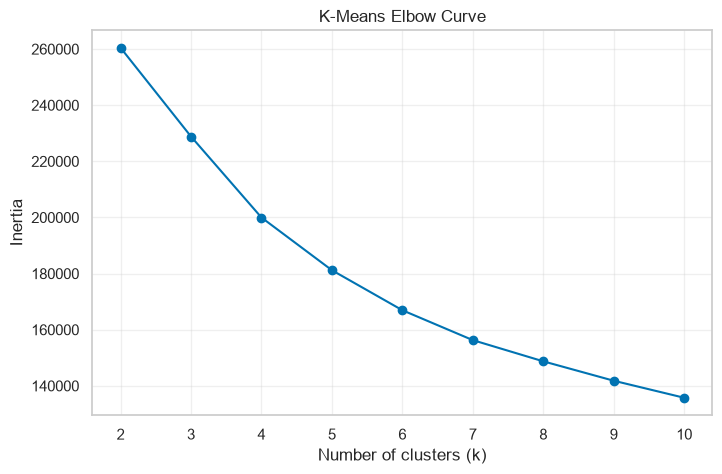

,k,inertia
0,2,260447.785197
1,3,228818.730508
2,4,199962.141419
3,5,181183.961707
4,6,166929.748717
5,7,156276.278323
6,8,148724.617976
7,9,141811.234247
8,10,135744.308661


In [6]:
k_values = range(2, 11)
inertias = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Curve")
plt.grid(True, alpha=0.3)
plt.show()

pd.DataFrame({"k": list(k_values), "inertia": inertias})

### Elbow choice

Inspect the elbow plot above and choose a `k` where the curve starts to flatten. The cell below computes silhouette scores for the same candidates as a secondary diagnostic, then selects the `k` with the highest silhouette score as a reproducible default. **Check this selected value against the elbow curve**: if the elbow clearly suggests a simpler solution, change `CHOSEN_K` manually and rerun the remaining cells. Silhouette is a supporting metric, not a replacement for interpreting the elbow and the domain.

In [7]:
# Secondary diagnostic to make the choice reproducible; sample for speed on larger datasets.
rng = np.random.RandomState(RANDOM_STATE)
sample_size = min(5000, X_scaled.shape[0])
sample_idx = rng.choice(X_scaled.shape[0], size=sample_size, replace=False)
X_sample = X_scaled[sample_idx]

diagnostics = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10)
    labels_sample = model.fit_predict(X_sample)
    diagnostics.append({
        "k": k,
        "sample_silhouette": silhouette_score(X_sample, labels_sample)
    })

diagnostics_df = pd.DataFrame(diagnostics)
display(diagnostics_df)
CHOSEN_K = int(diagnostics_df.loc[diagnostics_df["sample_silhouette"].idxmax(), "k"])
print("Default chosen k from sampled silhouette diagnostic:", CHOSEN_K)
print("Confirm this is reasonable against the elbow curve before finalizing.")

,k,sample_silhouette
0,2,0.523726
1,3,0.497089
2,4,0.292124
3,5,0.302532
4,6,0.267934
5,7,0.253844
6,8,0.260339
7,9,0.263310
8,10,0.263733


Default chosen k from sampled silhouette diagnostic: 2
Confirm this is reasonable against the elbow curve before finalizing.


## 3. Fit the final K-Means model

Fit K-Means to all prepared rows using the selected `k`, then attach cluster IDs to a copy of the original dataset for interpretation. Cluster IDs (`0`, `1`, …) are arbitrary names, not rankings.

In [8]:
kmeans = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_scaled)

clustered_df = df.copy()
clustered_df["Cluster"] = cluster_labels

print("Final model:", kmeans)
print("\nRows per cluster:")
display(clustered_df["Cluster"].value_counts().sort_index().to_frame("row_count"))
print("\nMean pollutant concentrations by cluster (original units):")
display(clustered_df.groupby("Cluster")[features].mean().round(2))
print("\nExample assigned rows:")
display(clustered_df[["City", "Date"] + features + ["Cluster"]].head(10))

Final model: KMeans(n_clusters=2, n_init=10, random_state=42)

Rows per cluster:


,row_count
Cluster,
0,4086
1,25445



Mean pollutant concentrations by cluster (original units):


,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene
Cluster,,,,,,,,,,,
0,141.33,249.93,50.42,64.21,79.41,37.67,8.19,30.92,44.03,9.07,25.04
1,53.32,95.74,11.47,21.99,23.49,21.49,1.22,11.48,32.74,2.15,5.33



Example assigned rows:


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Cluster
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,1
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,1
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,1
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,1
5,Ahmedabad,2015-01-06,NaN,NaN,45.41,38.48,81.50,NaN,45.41,45.76,46.51,5.42,10.83,0
6,Ahmedabad,2015-01-07,NaN,NaN,112.16,40.62,130.77,NaN,112.16,32.28,33.47,0.00,0.00,0
7,Ahmedabad,2015-01-08,NaN,NaN,80.87,36.74,96.75,NaN,80.87,38.54,31.89,0.00,0.00,0
8,Ahmedabad,2015-01-09,NaN,NaN,29.16,31.00,48.00,NaN,29.16,58.68,25.75,0.00,0.00,0
9,Ahmedabad,2015-01-10,NaN,NaN,NaN,7.04,0.00,NaN,NaN,8.29,4.55,0.00,0.00,1


## 4. Evaluate K-Means clustering

- **Silhouette score:** ranges from −1 to 1; higher generally means better-separated, more cohesive clusters.
- **Davies–Bouldin index:** lower is generally better; it compares within-cluster spread with separation between clusters.
- **Calinski–Harabasz score:** higher generally indicates dense, well-separated clusters.

These are internal clustering metrics, not accuracy scores. They do not prove that the clusters correspond to official AQI categories.

In [9]:
sil = silhouette_score(X_scaled, cluster_labels, sample_size=min(5000, len(cluster_labels)), random_state=RANDOM_STATE)
dbi = davies_bouldin_score(X_scaled, cluster_labels)
chi = calinski_harabasz_score(X_scaled, cluster_labels)

metrics_df = pd.DataFrame({
    "Metric": ["Silhouette Score", "Davies-Bouldin Index", "Calinski-Harabasz Score"],
    "Value": [sil, dbi, chi],
    "Preferred direction": ["Higher (max 1)", "Lower", "Higher"]
})
display(metrics_df)
print("Interpretation: compare these values across plausible k values; no single metric should be used alone.")

,Metric,Value,Preferred direction
0,Silhouette Score,0.512671,Higher (max 1)
1,Davies-Bouldin Index,1.542037,Lower
2,Calinski-Harabasz Score,7300.772481,Higher


Interpretation: compare these values across plausible k values; no single metric should be used alone.


## 5. PCA 2D visualization

PCA reduces the standardized pollutant features to two dimensions for visualization. Each point is one daily observation, colored by its K-Means cluster. PCA is used **only for plotting**; K-Means was fitted on the full scaled feature space.

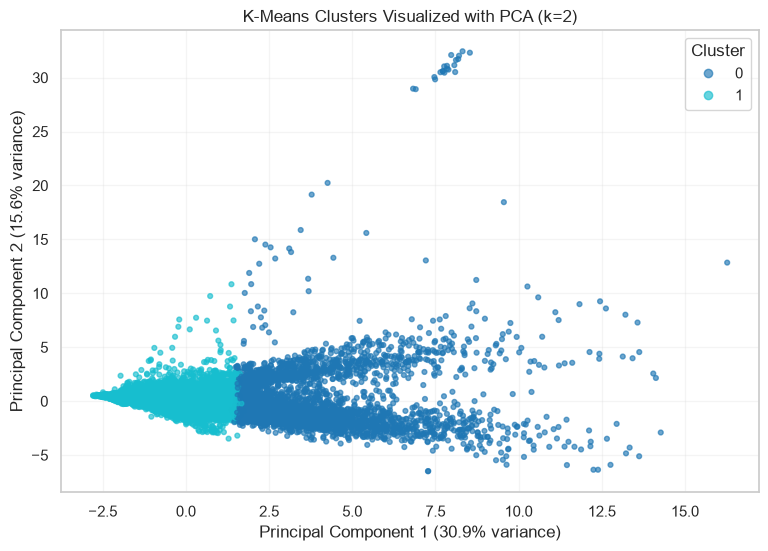

Total variance explained by 2 PCA components: 46.50%


In [10]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=cluster_labels, cmap="tab10", s=12, alpha=0.65
)
plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title(f"K-Means Clusters Visualized with PCA (k={CHOSEN_K})")
plt.legend(*scatter.legend_elements(), title="Cluster", loc="best")
plt.grid(True, alpha=0.2)
plt.show()

print("Total variance explained by 2 PCA components:",
      f"{pca.explained_variance_ratio_.sum()*100:.2f}%")

## 6. Interpretation and verification

Use the cluster means above to describe each cluster by its pollutant profile. For example, a cluster with higher average PM2.5/PM10 may represent a particulate-heavy profile, while a cluster with higher NO₂/NOx/CO may reflect a different pollution mixture. **Do not assign labels such as “Good” or “Hazardous” based only on cluster ID**; inspect the actual means and compare with official thresholds only if you add a separate, clearly documented analysis.

### Verification checklist
- [x] `AQI` and `AQI_Bucket` excluded from clustering features.
- [x] `City` and `Date` excluded from numerical feature matrix.
- [x] High-missingness `Xylene` excluded; remaining missing values median-imputed.
- [x] Features standardized before Euclidean-distance-based K-Means.
- [x] Elbow curve generated for k = 2 to 10.
- [x] Final cluster labels created.
- [x] Silhouette, Davies–Bouldin, and Calinski–Harabasz metrics calculated.
- [x] PCA 2D cluster plot generated.

**Caveat:** this dataset contains daily records from multiple cities. Clusters may partly reflect city-specific pollutant patterns as well as pollution severity. Treat them as pollutant-profile groups, not automatically as AQI categories.

# Part 2: Agglomerative Hierarchical Clustering
**Member:** Adithya

This part reuses everything above (`df`, `features`, `X_imputed`, `X_scaled`, `CHOSEN_K`, the fitted `kmeans`) so both algorithms are compared on identical data. `AQI` and `AQI_Bucket` are never used while fitting; `AQI_Bucket` is used only at the end for interpretation.

In [11]:
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet
from scipy.spatial.distance import pdist

sns.set_theme(style="whitegrid", palette="colorblind")
PALETTE = sns.color_palette("colorblind")
K = CHOSEN_K          # same k as the K-Means section

## 7. Hierarchical Clustering: Working Sample

Agglomerative clustering compares every pair of points. For all 29,531 rows that is about 436 million distances (several GB of memory), which is impractical. We therefore cluster a **random sample of 5,000 rows** (`random_state = 42`), the same size and seed as the K-Means diagnostic sample, so both algorithms can be scored on exactly the same rows.

In [12]:
N_SAMPLE = 5000
rng_h = np.random.RandomState(RANDOM_STATE)
hc_idx = rng_h.choice(X_scaled.shape[0], size=N_SAMPLE, replace=False)

X_hc      = X_scaled[hc_idx]                                   # scaled, used for clustering
X_hc_orig = pd.DataFrame(X_imputed[hc_idx], columns=features)  # original units, for profiling
df_hc     = df.iloc[hc_idx].reset_index(drop=True)

print("Sample shape:", X_hc.shape)
print("Pairwise distances in sample   :", f"{N_SAMPLE*(N_SAMPLE-1)//2:,}")
print("Pairwise distances in full data:", f"{len(X_scaled)*(len(X_scaled)-1)//2:,}")

Sample shape: (5000, 11)
Pairwise distances in sample   : 12,497,500
Pairwise distances in full data: 436,025,215


## 8. Dendrogram (Ward linkage)

A dendrogram shows the order in which clusters merge and the distance at which each merge happens. Tall vertical lines mean two very different groups were joined. A horizontal cut gives a flat clustering. With 5,000 leaves the full tree is unreadable, so only the last 30 merges are drawn; the number in brackets is how many points a branch holds.

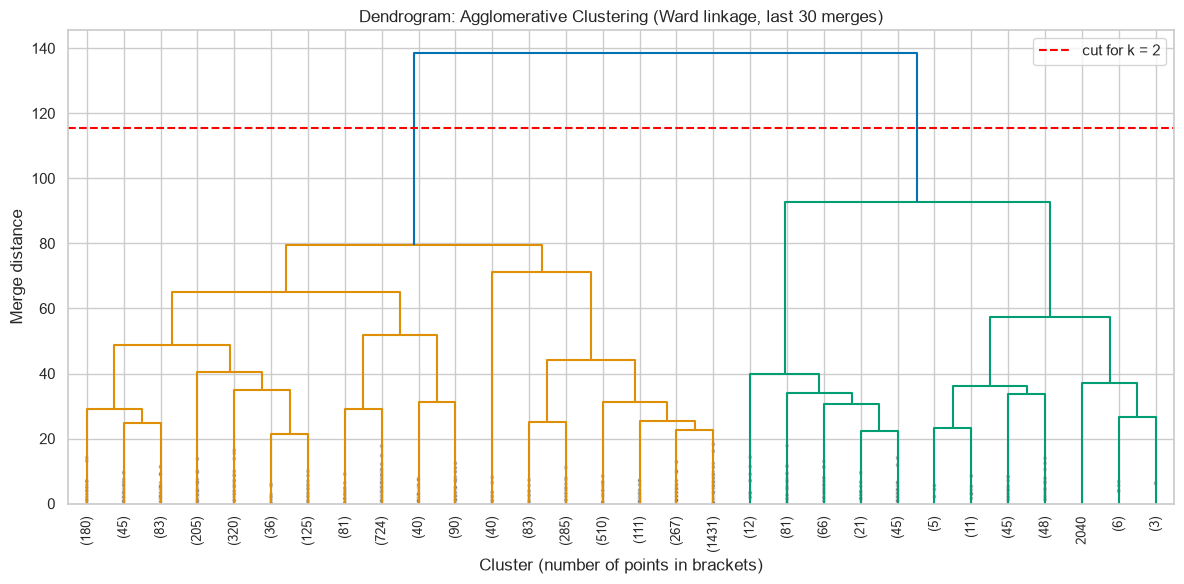

Last merge heights (largest first): [138.5  92.6  79.6  71.1  65.1  57.4]


In [13]:
Z_ward = linkage(X_hc, method="ward")

# a cut giving K clusters sits between the (K-1)th-last and Kth-last merge heights
cut_height = (Z_ward[-(K - 1), 2] + Z_ward[-K, 2]) / 2

plt.figure(figsize=(12, 6))
dendrogram(Z_ward, truncate_mode="lastp", p=30, leaf_rotation=90,
           leaf_font_size=9, show_contracted=True, color_threshold=cut_height)
plt.axhline(cut_height, color="red", linestyle="--", label=f"cut for k = {K}")
plt.title("Dendrogram: Agglomerative Clustering (Ward linkage, last 30 merges)")
plt.xlabel("Cluster (number of points in brackets)")
plt.ylabel("Merge distance")
plt.legend()
plt.tight_layout()
plt.show()

print("Last merge heights (largest first):", np.round(Z_ward[-6:, 2][::-1], 1))

### Observation: Dendrogram

___ (What does the plot show? Which merge has the biggest jump in height and what does that suggest about the natural number of clusters? How big are the branches below the cut?)

## 9. Choosing k for Ward Linkage

Hierarchical clustering has no elbow plot, so the dendrogram and the validity indices guide the choice. We score k = 2 to 8 with Ward linkage on the sample.

In [ ]:
def cluster_metrics(X, labels):
    return {"Silhouette (higher)": silhouette_score(X, labels),
            "Davies-Bouldin (lower)": davies_bouldin_score(X, labels),
            "Calinski-Harabasz (higher)": calinski_harabasz_score(X, labels)}

rows = []
for k in range(2, 9):
    lab = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_hc)
    rows.append({"k": k, **cluster_metrics(X_hc, lab), "smallest cluster": np.bincount(lab).min()})

ward_k_table = pd.DataFrame(rows).set_index("k")
display(ward_k_table.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col, color in zip(axes, ["Silhouette (higher)", "Davies-Bouldin (lower)", "Calinski-Harabasz (higher)"], PALETTE):
    ax.plot(ward_k_table.index, ward_k_table[col], "o-", color=color)
    ax.axvline(K, color="grey", linestyle="--", label=f"chosen k = {K}")
    ax.set_title(f"{col} vs. k (Ward)")
    ax.set_xlabel("Number of clusters (k)")
    ax.set_ylabel(col)
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: Choosing k

___ (Which k scores best on each index? Do they agree? Why is k = 2 used here? Mention that K-Means also uses k = 2, which keeps the comparison fair.)

## 10. Comparing Linkage Strategies

| Linkage | Distance between two clusters |
|---|---|
| **ward** | increase in total within-cluster variance if they are merged |
| **average** | mean distance over all point pairs |
| **complete** | distance between the two *farthest* points |
| **single** | distance between the two *closest* points |

All four are fitted with k = 2. The **cophenetic correlation** measures how faithfully the dendrogram preserves the original pairwise distances (closer to 1 is better).

In [ ]:
pair_dist = pdist(X_hc)
rows, linkage_labels = [], {}

for method in ["ward", "average", "complete", "single"]:
    Z = linkage(X_hc, method=method)
    coph = cophenet(Z, pair_dist)[0]
    lab = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(X_hc)
    linkage_labels[method] = lab
    rows.append({"Linkage": method, **cluster_metrics(X_hc, lab),
                 "Cophenetic corr.": coph, "Cluster sizes": np.bincount(lab).tolist()})

linkage_table = pd.DataFrame(rows).set_index("Linkage")
display(linkage_table.round(3))

### Observation: Linkage Comparison

Check the **Cluster sizes** column before trusting the scores. Average, complete and single linkage each put only a handful of points in one cluster and everything else in the other: they have found a few extreme outliers rather than a real grouping. Their Silhouette and Davies-Bouldin values look excellent only because one huge cluster dominates, so high scores alone can mislead.

**Cophenetic correlation caveat:** average linkage has the highest value, yet it still isolates just 2 points. Cophenetic correlation measures how faithfully the *tree* preserves pairwise distances; it does not say whether cutting the tree gives useful clusters. Ward's merge heights are also on a different scale (variance increase, not raw distance), so its value is not directly comparable.

___ (Which linkage gives usable, balanced clusters? Why is Ward the final choice despite its lower cophenetic correlation?)

## 11. Final Model: Agglomerative Clustering (Ward, k = 2)

In [ ]:
hier = AgglomerativeClustering(n_clusters=K, linkage="ward")
labels_h = hier.fit_predict(X_hc)

print("Rows per cluster (sample):")
display(pd.Series(labels_h).value_counts().sort_index().to_frame("row_count"))

display(pd.DataFrame(cluster_metrics(X_hc, labels_h), index=["Agglomerative (Ward, k=2)"]).round(3))

### Cluster Profiles

Mean pollutant concentration in each cluster, in the **original** units.

In [ ]:
profile = X_hc_orig.groupby(labels_h).mean().round(2)
profile["rows"] = np.bincount(labels_h)
display(profile)

profile[features].plot(kind="bar", figsize=(11, 5))
plt.title("Mean Pollutant Concentration per Hierarchical Cluster")
plt.xlabel("Cluster")
plt.ylabel("Mean concentration")
plt.xticks(rotation=0)
plt.legend(title="Pollutant", ncol=2)
plt.tight_layout()
plt.show()

### Observation: Final Model and Profiles

___ (What do the three metrics say about cluster quality? Describe each cluster by its pollutant profile: which cluster has higher PM2.5/PM10 and NO/NO2, and what kind of days that suggests.)

## 12. PCA Visualisation (2 Components)

PCA is fitted on the scaled sample. The K-Means model from the earlier section (fitted on **all** rows) is used to label the same 5,000 rows, so both plots show identical points.

In [ ]:
labels_k = kmeans.predict(X_hc)

pca_hc = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca_hc = pca_hc.fit_transform(X_hc)
print("Variance explained by 2 components:", round(pca_hc.explained_variance_ratio_.sum() * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, labs, title in [(axes[0], labels_h, "Agglomerative (Ward)"), (axes[1], labels_k, "K-Means")]:
    for c in range(K):
        m = labs == c
        ax.scatter(X_pca_hc[m, 0], X_pca_hc[m, 1], s=10, alpha=0.6, color=PALETTE[c], label=f"Cluster {c} (n={m.sum():,})")
    ax.set_title(f"{title}, k = {K}: PCA space")
    ax.set_xlabel(f"PC1 ({pca_hc.explained_variance_ratio_[0]:.1%} variance)")
    ax.set_ylabel(f"PC2 ({pca_hc.explained_variance_ratio_[1]:.1%} variance)")
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: PCA

___ (How much variance do 2 components keep, and how far can the 2D picture be trusted? Where do the small and large clusters sit? Do Ward and K-Means draw the boundary in the same place?)

## 13. t-SNE Visualisation

t-SNE is non-linear: it keeps **neighbourhoods** (close in 11-D stays close in 2-D) but not global distances, so cluster sizes and gaps in the picture should not be over-interpreted. One embedding is computed and coloured twice so the algorithms are compared on identical coordinates.

In [ ]:
tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_hc)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, labs, title in [(axes[0], labels_h, "Agglomerative (Ward)"), (axes[1], labels_k, "K-Means")]:
    for c in range(K):
        m = labs == c
        ax.scatter(X_tsne[m, 0], X_tsne[m, 1], s=10, alpha=0.6, color=PALETTE[c], label=f"Cluster {c} (n={m.sum():,})")
    ax.set_title(f"{title}, k = {K}: t-SNE")
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend()
plt.tight_layout()
plt.show()

### Observation: t-SNE

___ (Do the clusters appear as separate regions or one connected cloud? Where do the two algorithms disagree? Why can t-SNE not be used to judge cluster size?)

## 14. K-Means vs. Hierarchical: Comparison Table

Both algorithms are scored on the **same 5,000 rows**. Calinski-Harabasz grows with the number of rows, so these values cannot be compared with the full-data value in the K-Means section.

In [ ]:
comparison = pd.DataFrame(
    [cluster_metrics(X_hc, labels_k), cluster_metrics(X_hc, labels_h)],
    index=["K-Means (k=2)", "Agglomerative Ward (k=2)"]
)
comparison["Cluster sizes"] = [np.bincount(labels_k).tolist(), np.bincount(labels_h).tolist()]
display(comparison.round(3))

print("Agreement between the two clusterings (Adjusted Rand Index):",
      round(adjusted_rand_score(labels_k, labels_h), 3))

### Observation: Comparison

___ (Which algorithm scores better on each metric? How similar are the two clusterings? Mention trade-offs: K-Means is fast and uses all rows; hierarchical gives the dendrogram but needs a sample here.)

## 15. Post-hoc Validation against AQI Buckets

Only **after** clustering do we compare with the known `AQI_Bucket`, purely for interpretation. It was never used in fitting.

In [ ]:
order = ["Good", "Satisfactory", "Moderate", "Poor", "Very Poor", "Severe"]
valid = df_hc["AQI_Bucket"].notna().values

ct = pd.crosstab(labels_h[valid], df_hc.loc[valid, "AQI_Bucket"])
ct = ct[[c for c in order if c in ct.columns]]
ct.index.name = "Hierarchical cluster"
display(ct)

print("Adjusted Rand Index vs. AQI_Bucket:",
      round(adjusted_rand_score(df_hc.loc[valid, "AQI_Bucket"], labels_h[valid]), 3))

plt.figure(figsize=(8, 3.5))
sns.heatmap(ct.div(ct.sum(axis=1), axis=0), annot=True, fmt=".2f", cmap="viridis")
plt.title("Share of Each AQI Bucket within Each Hierarchical Cluster")
plt.xlabel("Known AQI bucket")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

### Observation: Validation

___ (Which buckets dominate each cluster? Is the low ARI a problem? AQI buckets are cut-points on the single worst pollutant while clusters use all 11 pollutants. Also note the data holds many cities, so clusters may partly reflect city-specific patterns.)

## 16. Summary (Hierarchical)

- **Final model:** Agglomerative Clustering, Ward linkage, k = 2, fitted on a 5,000-row random sample (same size and seed as the K-Means diagnostic sample).
- **Linkage choice:** ___
- **Metrics:** see the Section 11 and Section 14 tables.
- **Visualisations:** dendrogram, PCA and t-SNE for both algorithms.
- **Limitation:** hierarchical clustering ran on a sample because the full distance matrix is too large; results may differ slightly with another sample.